# 6. Hafta | Kendi Projemin Veri Analizi — Ekip Teslim Şablonu

**Proje:** DepGuard – Açık Kaynak Yazılımlarda Güvenlik Açığı Tespiti ve Risk Analizi


## A. Veri tanıtımı
- Veri setinin adı ve bağlantısı: GitHub Advisory Database
https://github.com/github/advisory-database
- Veri kaynağı / lisans / erişim tarihi: GitHub Advisory Database, CC-BY 4.0 lisansı. 08.11.2026.
- CSV mi, JSON mu? JSON. Veriler GitHub REST API aracılığıyla alınacaktır.
- Satır ve sütunların anlamı: Her satır bir güvenlik açığı kaydını temsil edecektir. Sütunlarda güvenlik açığının kimliği, açıklaması, önem derecesi, yayınlanma tarihi, etkilenen Python paketi ve etkilenen sürüm aralığı gibi bilgiler bulunacaktır.
- Ölçü birimi ve gözlem sayısı: Gözlem birimi bir güvenlik açığı kaydıdır. İlk veri toplama aşamasında API üzerinden en fazla 100 kayıt alınacaktır. Kesin gözlem sayısı veri indirildikten sonra belirlenecektir.
- Gerçek mi / açık kaynak mı / temsili mi? Gerçek, kamuya açık güvenlik açığı kayıtlarından oluşan açık kaynak veri.
- Ekip üyelerinin görevleri: Veri toplama, veri düzenleme, analiz ve görselleştirme görevleri proje ekibi tarafından yürütülecektir.

## B. Başlangıç: temsili veriyle çalışan örnek
Bu bölümde veri setinin Python ortamına aktarılması işlemi yapılır. DepGuard projesinde GitHub Advisory Database API kullanılarak Python (pip) ekosistemindeki güvenlik açığı kayıtları JSON formatında alınır. Daha sonra Pandas kütüphanesi yardımıyla bu kayıtlar tablo biçimine dönüştürülerek incelenmeye hazır hâle getirilir.

In [6]:
import json, requests
from pathlib import Path
import pandas as pd

Path("veri").mkdir(exist_ok=True)

url = "https://api.github.com/advisories"
params = {"ecosystem": "pip", "type": "reviewed", "per_page": 100}
r = requests.get(url, params=params,
                 headers={"Accept": "application/vnd.github+json"}, timeout=30)
r.raise_for_status()
kayitlar = r.json()

# Ham JSON'u sakla (kaynak kanıtı)
with open("veri/advisory_ham.json", "w", encoding="utf-8") as f:
    json.dump(kayitlar, f, ensure_ascii=False, indent=2)

# Her satır = bir güvenlik açığı kaydı (credits gibi kişi alanlarını almıyoruz)
satirlar = []
for k in kayitlar:
    vul = k.get("vulnerabilities") or []
    satirlar.append({
        "ghsa_id": k.get("ghsa_id"),
        "cve_id": k.get("cve_id"),
        "ozet": k.get("summary"),
        "onem": k.get("severity"),
        "cvss_puani": (k.get("cvss") or {}).get("score"),
        "yayin_tarihi": k.get("published_at"),
        "paketler": "; ".join(sorted({v["package"]["name"] for v in vul if v.get("package")})),
        "etkilenen_surum": "; ".join(v.get("vulnerable_version_range") or "" for v in vul),
    })

veri = pd.DataFrame(satirlar)
veri["yayin_tarihi"] = pd.to_datetime(veri["yayin_tarihi"])
print(veri.head())

               ghsa_id           cve_id  \
0  GHSA-r4hm-p9f9-fj9v   CVE-2026-55649   
1  GHSA-fqpv-mq26-pr4j   CVE-2026-46429   
2  GHSA-9fpx-fr6j-2vh6   CVE-2026-33050   
3  GHSA-64vx-6h2c-rjh7   CVE-2026-61536   
4  GHSA-gh9r-c94j-cmp5  CVE-2026-115878   

                                                ozet    onem  cvss_puani  \
0  GeoNode has Stored XSS in Documents metadata a...  medium         6.3   
1               GeoNode has Unrestricted File Upload  medium         5.5   
2  GeoNode has OS command injection via uploaded ...    high         8.8   
3  Banks: Unsafe importlib.import_module of attac...    high         7.5   
4  Stanza: RCE via pickle deserialization in the ...    high         7.8   

               yayin_tarihi paketler etkilenen_surum  
0 2026-11-06 19:50:34+00:00  GeoNode         < 5.0.3  
1 2026-11-06 19:41:23+00:00  GeoNode        <= 5.0.2  
2 2026-11-06 19:39:38+00:00  GeoNode         < 5.1.0  
3 2026-11-05 17:51:02+00:00    banks        <= 2.4.2  
4 2026-11

## C. Veri inceleme ve hesaplama
Bu bölümde alınan verilerin genel yapısı incelenir. Veri setindeki satır ve sütun sayıları belirlenir, eksik değerler kontrol edilir ve uygun sayısal değişkenler üzerinde toplam ve ortalama hesaplamaları yapılır. DepGuard kapsamında güvenlik açıklarının CVSS puanları ve önem dereceleri değerlendirilir. Eksik CVSS puanları hesaplamalara dâhil edilmez.

In [12]:
print("Boyut:", veri.shape)
print("Eksikler:\n", veri.isna().sum())
print("Toplam kayıt sayısı:", len(veri))
print("Ortalama CVSS puanı (0-10):", round(veri["cvss_puani"].mean(), 2))
print("Önem dağılımı:\n", veri["onem"].value_counts())
print("Kumulatif Risk Skoru Toplamı:", round(veri["cvss_puani"].sum(), 2))

Boyut: (100, 8)
Eksikler:
 ghsa_id             0
cve_id             13
ozet                0
onem                0
cvss_puani         21
yayin_tarihi        0
paketler            0
etkilenen_surum     0
dtype: int64
Toplam kayıt sayısı: 100
Ortalama CVSS puanı (0-10): 6.58
Önem dağılımı:
 onem
medium      47
high        44
low          6
critical     3
Name: count, dtype: int64
Kumulatif Risk Skoru Toplamı: 519.7


## D. Grafik ve sonuç dosyaları
Bu bölümde analiz edilen veriler grafiklerle görselleştirilir. Güvenlik açıklarının önem derecelerine veya CVSS puanlarına göre dağılımı gösterilebilir. Grafiklerde başlık, eksen adları ve ölçü birimleri belirtilir. Oluşturulan grafikler ve analizde kullanılan veri dosyası sonuc/ klasörüne kaydedilir.

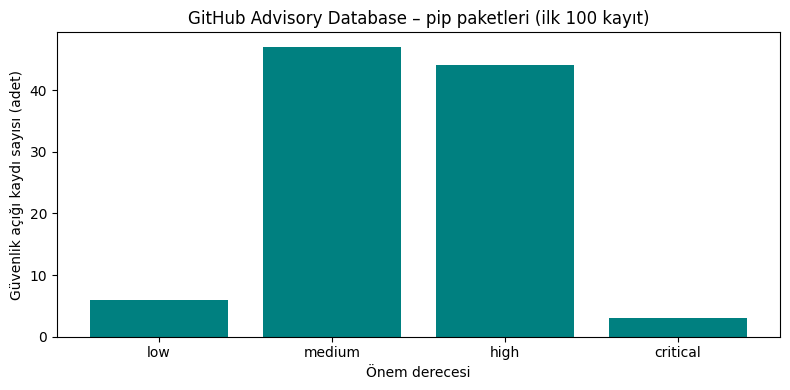

In [15]:
#pip install -q matplotlib requests pandas

from pathlib import Path
import matplotlib.pyplot as plt
import pandas as pd
import requests

url = "https://api.github.com/advisories"
headers = {
    "User-Agent": "Colab-Advisory-Fetcher",
    "Accept": "application/vnd.github+json"
}
parametreler = {
    "type": "reviewed",
    "ecosystem": "pip",
    "per_page": 100,
    "sort": "published",
    "direction": "desc"
}

cevap = requests.get(url, headers=headers, params=parametreler, timeout=30)
cevap.raise_for_status()
veri = pd.json_normalize(cevap.json())

klasor = Path("sonuc")
klasor.mkdir(exist_ok=True)

sira = ["low", "medium", "high", "critical"]

sayim = veri["severity"].str.lower().value_counts().reindex(sira).fillna(0)

fig, ax = plt.subplots(figsize=(8, 4))
ax.bar(sayim.index, sayim.values, color="teal")
ax.set_xlabel("Önem derecesi")
ax.set_ylabel("Güvenlik açığı kaydı sayısı (adet)")
ax.set_title("GitHub Advisory Database – pip paketleri (ilk 100 kayıt)")
fig.tight_layout()

fig.savefig(klasor / "grafik.png", dpi=160)
veri.to_csv(klasor / "kullanilan_veri.csv", index=False)

plt.show()


## E. Akademik yorum

**Veri kaynağı ve değişken:** Bu çalışmada GitHub Advisory Database üzerinden Python (pip) ekosistemine ait incelenmiş güvenlik açığı kayıtları kullanılmıştır. Veri setinde güvenlik açığı kimliği, açıklaması, önem derecesi, yayınlanma tarihi, etkilenen paket adı ve sürüm bilgileri incelenmiştir.

**Toplam / ortalama ve birimler:** Analiz kapsamında toplam [kayıt sayısı] güvenlik açığı kaydı incelenmiştir. Sayısal CVSS puanlarının ortalaması [ortalama değer] olarak hesaplanmıştır. CVSS puanı birimi olmayan sayısal bir risk puanıdır.

**Grafikte görülen bulgu:** Oluşturulan grafikte [grafikte gözlemlenen temel bulgu] görülmüştür. Bu sonuç, incelenen veri kümesindeki güvenlik açıklarının dağılımı hakkında bilgi vermektedir.

**Sınırlılıklar ve ölçemediği şeyler:** Çalışma yalnızca veri kaynağında yayımlanmış ve incelenmiş güvenlik açıklarını kapsamaktadır. Henüz keşfedilmemiş güvenlik açıklarını, gerçek saldırı sıklığını veya bir paketin kesin olarak güvenli olup olmadığını ölçmemektedir.

**Ekipçe yapılan işlem:** Ekip tarafından veri kaynağı araştırılmış, API aracılığıyla kayıtlar toplanmış, Python ve Pandas kullanılarak veriler düzenlenmiş, temel istatistiksel analizler ve grafik çalışmaları gerçekleştirilmiştir.

*   **[kayıt sayısı]** Analiz edilen toplam güvenlik açığı kaydı sayısı.
*   **[ortalama değer]** CVSS puanlarının ortalaması.
*   **[grafikte gözlemlenen temel bulgu]** Grafikte gördüğünüz sonuç.

| Kütüphane | Görevi |
| :--- | :--- |
| **requests** | GitHub API üzerinden veri çekmek |
| **pandas** | JSON verilerini tabloya dönüştürmek, analiz etmek |
| **matplotlib** | Grafik oluşturmak |